# Section 3 – Unsupervised learning – clustering
In this unsupervised learning task, the objective is to cluster Reddit comments based on the words used
within the comments in them. The aim is to identify patterns and group comments with similar words
together.

In [1]:
%pip install nltk
import nltk
nltk.download('punkt')
nltk.download('wordnet')
%pip install WordCloud

Note: you may need to restart the kernel to use updated packages.


[nltk_data] Downloading package punkt to
[nltk_data]     /home/students/s346259/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /home/students/s346259/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score, adjusted_mutual_info_score

from wordcloud import WordCloud

In [3]:
data = pd.read_csv(f"without_stopwords_150.csv")

#(fixed)
    # # we actually forgot to remove duplicates/empty rows after removing stopwords, so "we do it now" by creating a mask
    # mask=[]
    # for index, row in data.iterrows():
    #     try:
    #         if len(row['body'].strip()) == 0:
    #             mask.append(False)
    #         else:            
    #             mask.append(True)
    #     except:#if NaN
    #         mask.append(False)
    # data = data[mask]

#read npy file (pre-processing was done in 'unsupervised-pre-processing.ipynb')
X = np.load('X_reduced_150_stemmer_BoW.npy')

#X = X[mask]

In [4]:
#check same number of samples
print(X.shape)
print(data.shape)

(739344, 1000)
(739344, 4)


## KMeans
### Determine the number of clusters

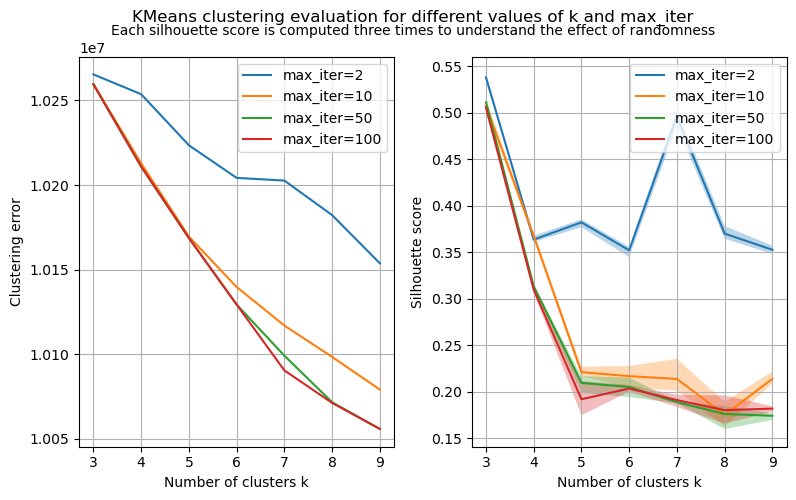

In [5]:
clustering_results = {}
#dictionary containing the list of kmeans results for each k
# k -> [kmeans_result1, kmeans_result2, ...]
# (we execute kmeans more than once for each k to understand how max_iter affects the results)

k_values=pd.concat([pd.Series(range(3, 10, 1))])
max_iter_values = [2, 10, 50, 100] #150, 200]#150 and 200 gave same results to 100

#Performing KMeans for different values of k
for k in k_values:
    for max_iter in max_iter_values:
        kmeans = KMeans(
        init='random', #centroids are initialized randomly
        random_state=42, 
        n_init='auto', #number of times the k-means algorithm will be run with different centroid seeds. 'auto' uses a default value based on init
        max_iter=max_iter,
        tol=1e-4,
        n_clusters=k
        )
        if clustering_results.get(k) is None:
            clustering_results[k] = []
        clustering_results[k].append(kmeans.fit(X))
        #print(f"Fitted KMeans with {k} clusters")#just to have a reference to how much time it's taking to execute

#Computing silhouette scores
n_sample=10000#number of samples to use for silhouette calculation, to speed up the process
#n_sample = 5

fig, axs = plt.subplots(1,2, figsize=(8, 5))
# plt.title("KMeans clustering evaluation for different values of k and max_iter")
# fig.text(0.5, 0.92, "Each silhouette score is computed three times to understand the effect of randomness)", ha="center", fontsize=10)
fig.suptitle("KMeans clustering evaluation for different values of k and max_iter", y=0.99)
fig.text(
    0.5, 0.94,
    "Each silhouette score is computed three times to understand the effect of randomness",
    ha="center", fontsize=10
)
axs[0].set_xlabel("Number of clusters k")
axs[0].set_ylabel("Clustering error")
axs[0].grid()
axs[1].set_xlabel("Number of clusters k")
axs[1].set_ylabel("Silhouette score")
axs[1].grid()
plt.tight_layout()

"""
we have
clustering_results = {
    3: [kmeans_result_100_iteration, kmeans_result_150_iteration, kmeans_result_200_iteration],
    4: [kmeans_result_100_iteration, kmeans_result_150_iteration, kmeans_result_200_iteration],
    ...
} 
"""
max_iter_index = 0
for max_iter in max_iter_values:

    #plot clustering error for each max_iter
    error_values = []
    for k in k_values:
        error_values.append(clustering_results[k][max_iter_index].inertia_)
    axs[0].plot(
        k_values,
        error_values,
        label=f"max_iter={max_iter}"
    )

    #silhouette scores for each max_iter
    silhouette_scores = np.zeros((len(k_values), 3), dtype=float)
    for i in range(3):#execute more than once to understand how randomness (of silhouette sampling) affects the results
        for k, clustering_result in clustering_results.items():
            k_index = k - 3#k starts from 3 -> subtract 3 to have the index of the silhouette_scores matrix
            try:
                silhouette_scores[k_index, i] = silhouette_score(X, clustering_result[max_iter_index].labels_, sample_size=n_sample)
            except ValueError as e:
                print(f"Skipping silhouette k={k}, max_iter={max_iter} calculation due to error: {e}")
                silhouette_scores[k_index, i] = -1
    y_min = silhouette_scores.min(axis=1)
    y_max = silhouette_scores.max(axis=1)
    y_avg = silhouette_scores.mean(axis=1)
    axs[1].plot(k_values, y_avg, label=f"max_iter={max_iter}")
    axs[1].fill_between(k_values, y_min, y_max, alpha=0.3)

    max_iter_index+=1

axs[0].legend()
axs[1].legend()

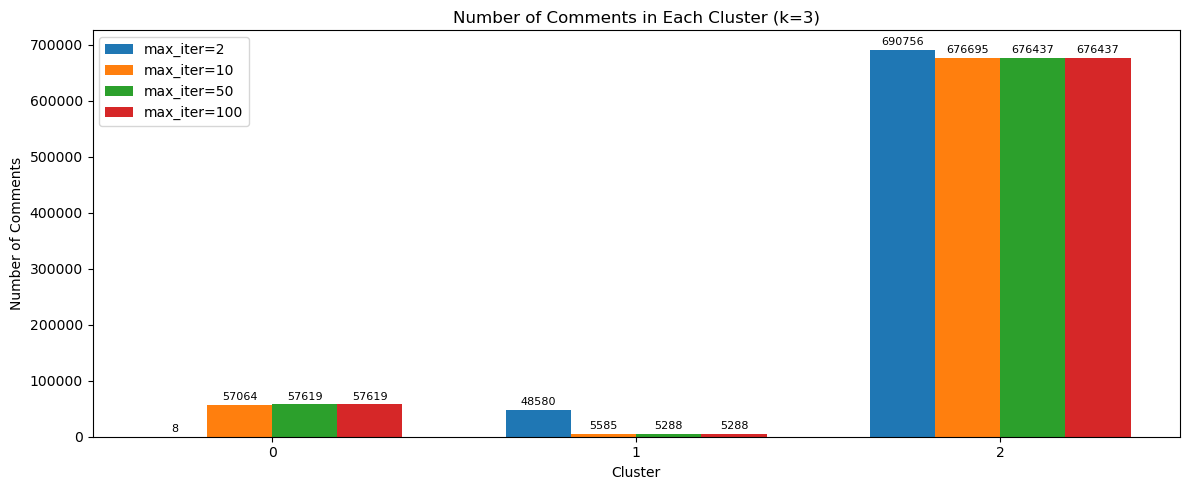

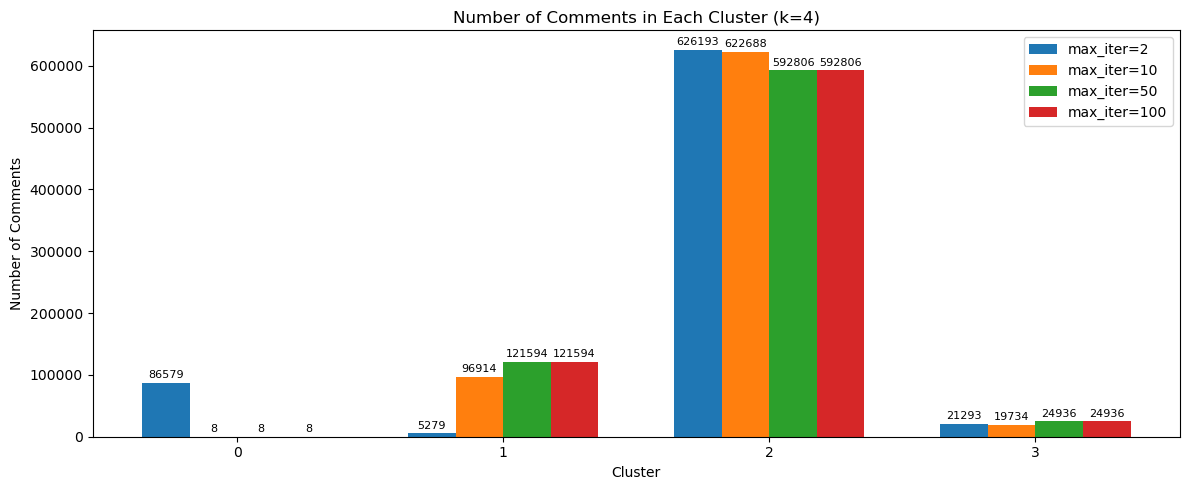

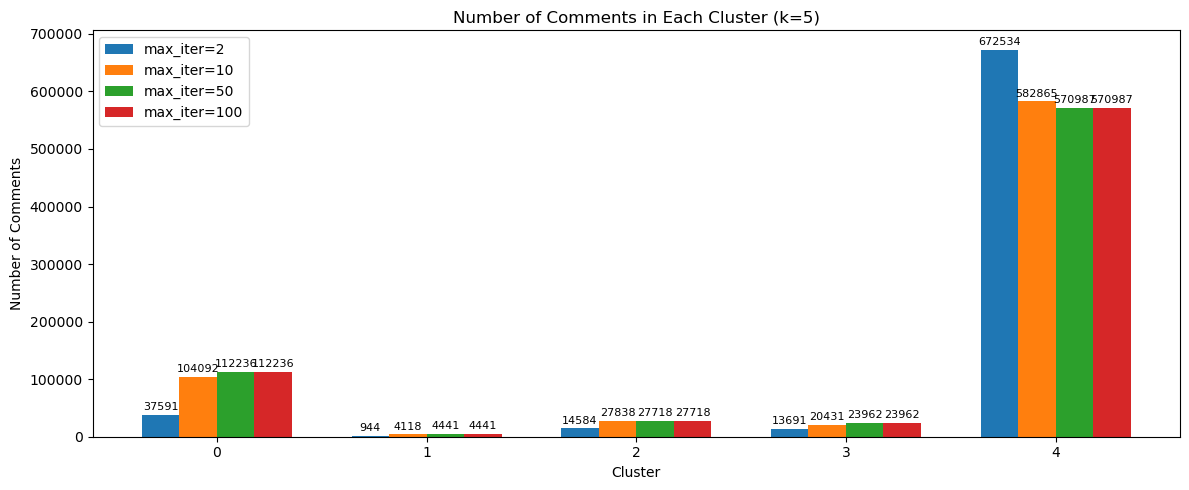

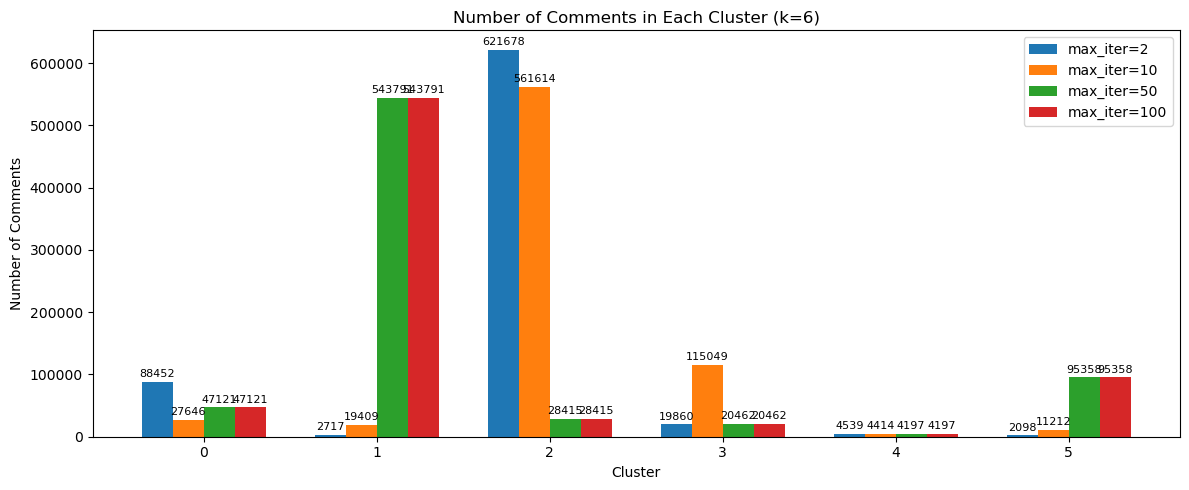

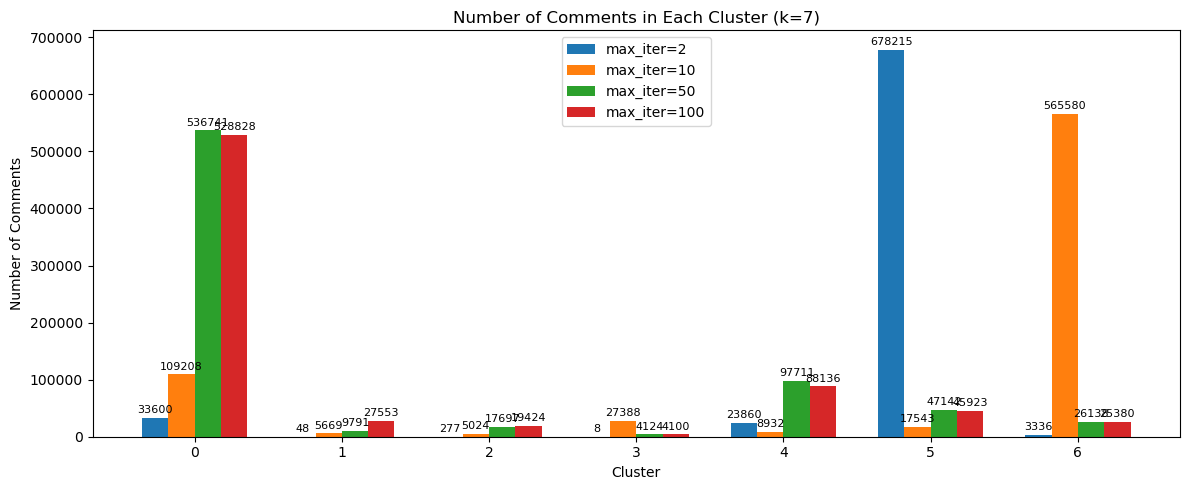

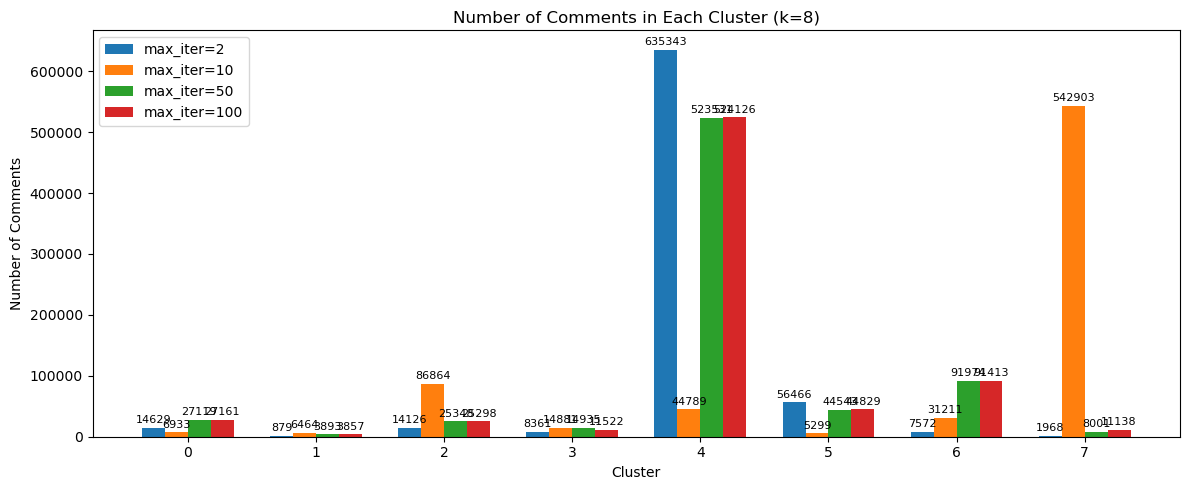

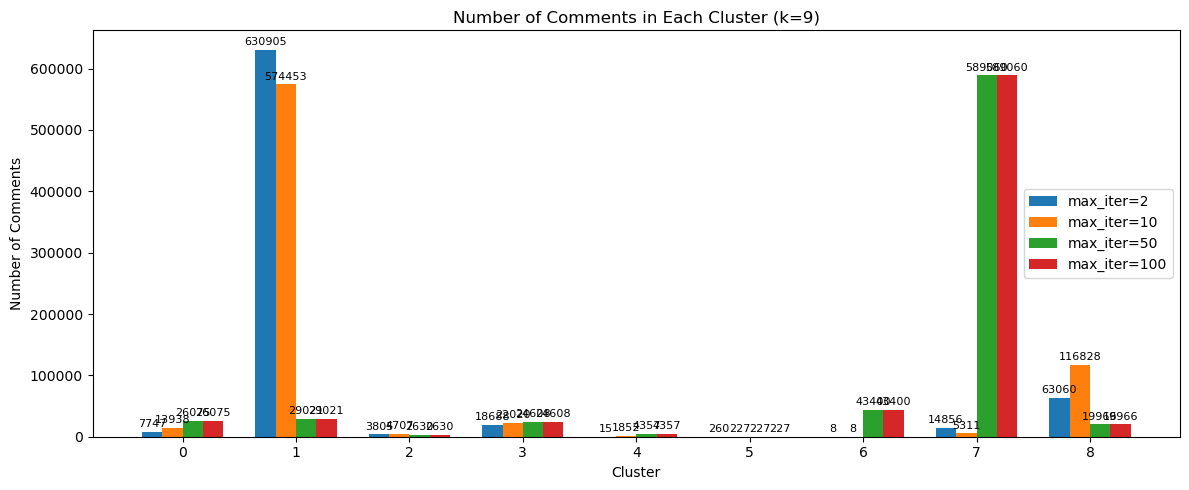

In [8]:
# #Plot the number of comments for each cluster and save the labels
# for k, clustering_result in clustering_results.items():
#     #clustering_result is a list: [kmeans_result_100_iteration, kmeans_result_150_iteration, kmeans_result_200_iteration]
#     max_iter_index = max_iter_values.index(max_iter)
#     cluster_sizes = pd.Series(clustering_result[max_iter_index].labels_).value_counts()
#     plt.figure(figsize=(10, 5))
#     plt.title(f"Number of Comments in Each Cluster (k={len(cluster_sizes)})")
#     plt.xlabel("Cluster")
#     plt.ylabel("Number of Comments") 
#     plt.xticks(cluster_sizes.index)
#     for max_iter in max_iter_values:
#         plt.bar_label(plt.bar(cluster_sizes.index, cluster_sizes.values))
#         plt.bar(cluster_sizes.index, cluster_sizes.values)
#         #label 
#     plt.show()
#     #print("Cluster sizes:\n", cluster_sizes)

#     np.save(f"labels_k_{k}_max_iter_{max_iter}.npy", clustering_result[max_iter_index].labels_)

# Plot comments per cluster for each k and each max_iter, and save labels
for k, clustering_result in clustering_results.items():
    # clustering_result = [model_for_100, model_for_150, model_for_200]
    plt.figure(figsize=(12, 5))

    n_runs = len(max_iter_values)
    width = 0.22
    group_gap = 0.35  # extra space between consecutive cluster groups
    x = np.arange(k) * (n_runs * width + group_gap)
    
    for i, (max_iter, model) in enumerate(zip(max_iter_values, clustering_result)):
        cluster_sizes = pd.Series(model.labels_).value_counts().sort_index()
        counts = cluster_sizes.reindex(range(k), fill_value=0).values

        bars = plt.bar(x + i * width, counts, width=width, label=f"max_iter={max_iter}")
        plt.bar_label(bars, padding=2, fontsize=8)

        np.save(f"labels_k_{k}_max_iter_{max_iter}.npy", model.labels_)

    plt.title(f"Number of Comments in Each Cluster (k={k})")
    plt.xlabel("Cluster")
    plt.ylabel("Number of Comments")
    plt.xticks(x + width * (n_runs - 1) / 2, range(k))
    plt.legend()
    plt.tight_layout()
    plt.show()

In [9]:
numberOfChoosenClusters= int(input("Number of clusters to choose (k): "))
max_iter_index= int(input("Index of max_iter to choose (0-2): "))
indexOfChoosenCluster=k_values[k_values==numberOfChoosenClusters].index[0]
data["cluster"]= clustering_results.get(numberOfChoosenClusters)[max_iter_index].labels_

Number of clusters to choose (k):  3
Index of max_iter to choose (0-2):  3


### User Distribution Analysis
Analyze how the users are distributed (each user can be assigned to more clusters because we
are clustering comments). 
#### Show the ECDF of number of clusters assigned to each user.

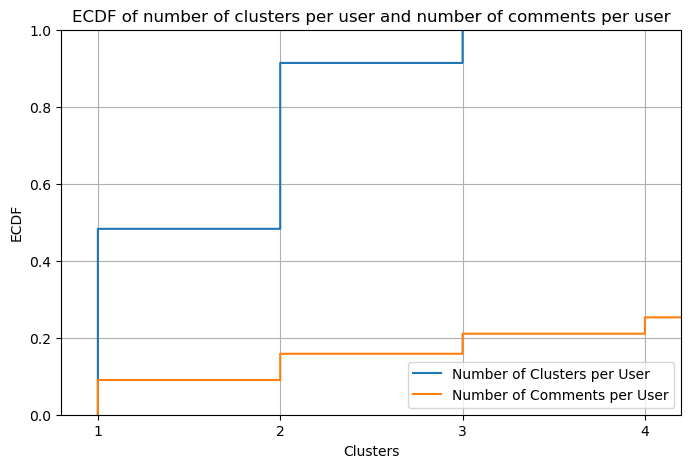

In [19]:
user_clusters = data.groupby('author')['cluster'].nunique().reset_index()#grouping by author
#user clusters is now a series with author and number of clusters
user_clusters.columns = ['author', 'num_clusters']#turn it into a DF

# Filter user_clusters to only those authors who have multiple comments
# authors_with_multiple_comments = data.groupby('author')['body'].nunique()
# authors_with_multiple_comments = authors_with_multiple_comments[authors_with_multiple_comments > 1].index
# user_clusters = user_clusters[user_clusters['author'].isin(authors_with_multiple_comments)]

user_comments = data.groupby('author')['body'].nunique().reset_index()
user_comments.columns = ['author', 'num_comments']

plt.figure(figsize=(8, 5))

sns.ecdfplot(data=user_clusters, x='num_clusters')
plt.ylabel('ECDF')
plt.xlabel('Clusters')
plt.title('ECDF of number of clusters per user and number of comments per user')

#plot ECDF of number of comments per user
sns.ecdfplot(data=user_comments, x='num_comments')
plt.grid(True)
x_min = 1
x_max = user_clusters['num_clusters'].max()+1
plt.xlim(0.8, x_max+0.2)
plt.xticks(range(1, x_max+1))
plt.legend(['Number of Clusters per User', 'Number of Comments per User'])

plt.show()

#### Use the first two components of the ~~PCA~~ TruncatedSVD. Then visualize on these two dimensions to gain insights into their distribution and separability

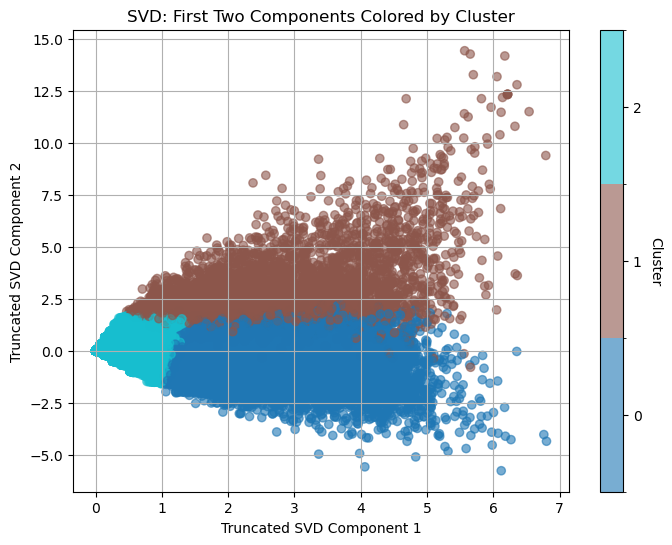

In [11]:
unique_clusters = np.sort(data['cluster'].unique())
cluster_to_idx = {cluster: idx for idx, cluster in enumerate(unique_clusters)}
color_idx = data['cluster'].map(cluster_to_idx)

cmap = plt.get_cmap('tab10', len(unique_clusters))
norm = plt.matplotlib.colors.BoundaryNorm(
    boundaries=np.arange(len(unique_clusters) + 1) - 0.5,
    ncolors=len(unique_clusters)

)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X[:, 0], X[:, 1], c=color_idx, cmap=cmap, norm=norm, alpha=0.6)
plt.xlabel('Truncated SVD Component 1')
plt.ylabel('Truncated SVD Component 2')
plt.title('SVD: First Two Components Colored by Cluster')
cbar = plt.colorbar(scatter, ticks=np.arange(len(unique_clusters)))
cbar.set_ticklabels(unique_clusters)
cbar.set_label('Cluster', rotation=270, labelpad=15)
plt.grid(True)
plt.show()

### Cluster analysis
Analyze the characteristics of each cluster. This might involve examining the most frequent
words in each cluster (try word cloud). HINT: the most used words are not always the most
representative, for example word ‘the’ will be very popular in every cluster if you didn’t remove it from the dataset. Try to understand which are the most representative

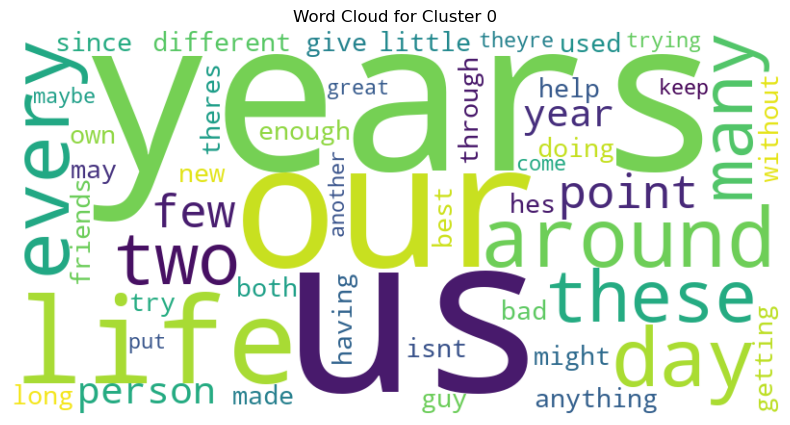

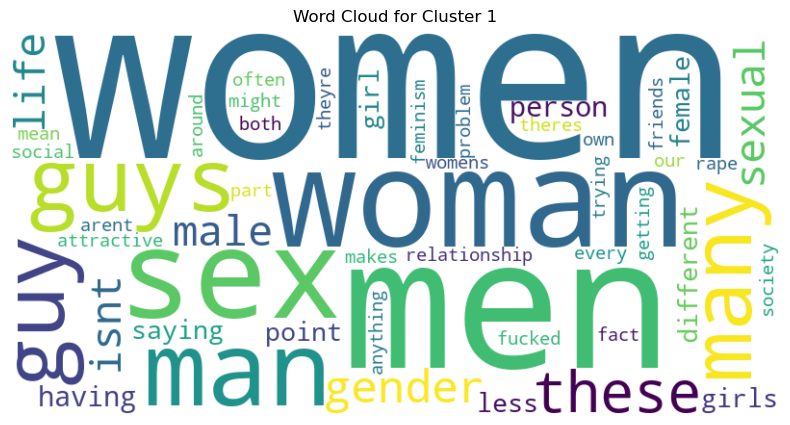

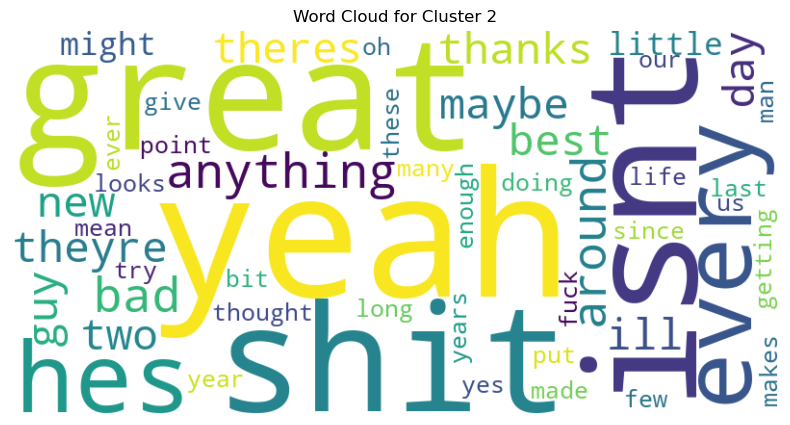

In [12]:
#Group by cluster and concatenate all comments in each cluster, then compute TF-IDF to understand important words in each cluster
cluster_documents=data[['body','cluster']].groupby('cluster').agg(' '.join).reset_index()
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(cluster_documents['body'])
terms = tfidf_vectorizer.get_feature_names_out()

#For each cluster, get the top 50 words by TF-IDF score and plot a word cloud
for cluster_num in range(numberOfChoosenClusters):
    tfidf_scores = tfidf_matrix[cluster_num].toarray().flatten()
    top_indices = np.argsort(tfidf_scores)[-50:]  # Get indices of top 50 words
    top_terms = {terms[i]: tfidf_scores[i] for i in top_indices}

    wordcloud = WordCloud(width=800, height=400, background_color='white').generate_from_frequencies(top_terms)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(f'Word Cloud for Cluster {cluster_num}')
    plt.show()

Finally, analyze and visualize how the subreddit are distributed among the found clusters. Are there pure clusters where only few related
subreddits end up?

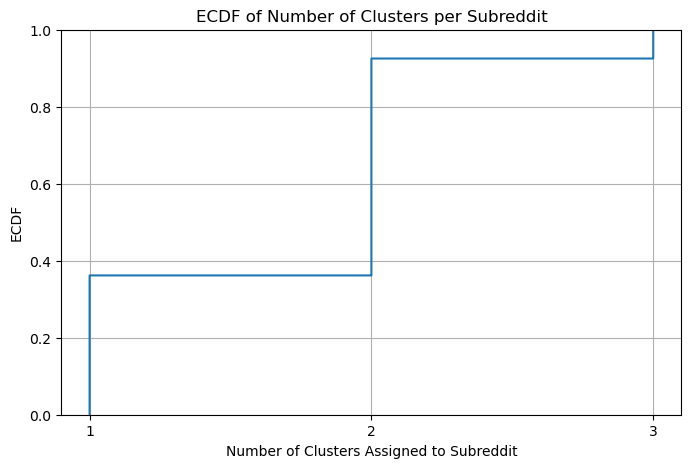

In [20]:
subreddit_cluster = data.groupby('subreddit')['cluster'].nunique().reset_index()#grouping by subreddit
#subreddit clusters is now a series with subreddit and number of clusters
subreddit_cluster.columns = ['subreddit', 'num_clusters']#turn it into a DF

# Filter subreddit_cluster to only those subreddits that have multiple comments
subreddits_with_multiple_comments = data.groupby('subreddit')['body'].nunique()
subreddits_with_multiple_comments = subreddits_with_multiple_comments[subreddits_with_multiple_comments > 1].index
subreddit_cluster = subreddit_cluster[subreddit_cluster['subreddit'].isin(subreddits_with_multiple_comments)]

plt.figure(figsize=(8, 5))
sns.ecdfplot(data=subreddit_cluster, x='num_clusters')
plt.title('ECDF of Number of Clusters per Subreddit')
plt.xlabel('Number of Clusters Assigned to Subreddit')
plt.ylabel('ECDF')
plt.xticks(range(1, subreddit_cluster['num_clusters'].max()+1))
plt.grid(True)
plt.show()

Cluster 0 has 57619 comments
Cluster 1 has 5288 comments
Cluster 2 has 676437 comments


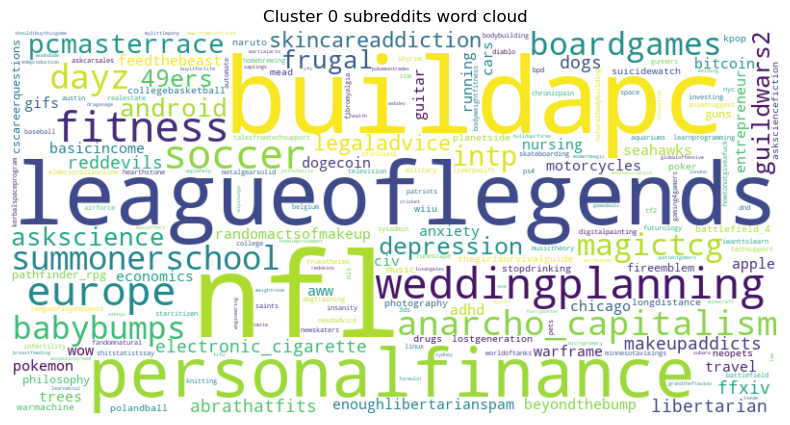

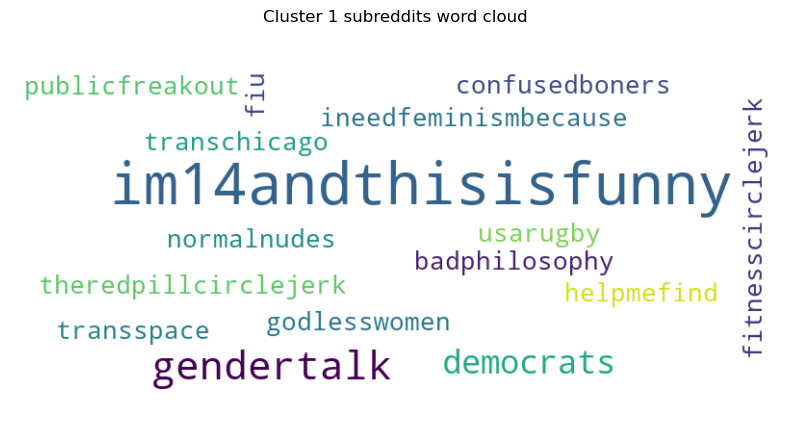

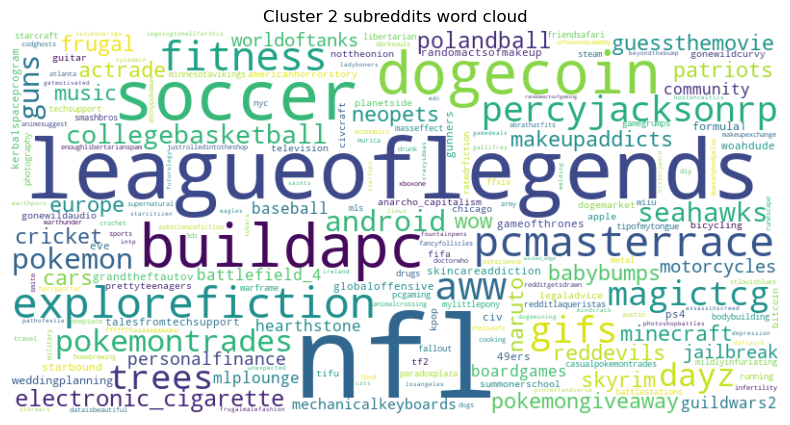

In [14]:
subredditsNames = []

#compute TF-IDF for subreddits in each cluster, to understand which subreddits are more important in each cluster,
#then plot a word cloud for each cluster
for i in range(0, numberOfChoosenClusters):
    cluster_sizes = data['cluster'].value_counts()
    print(f"Cluster {i} has {cluster_sizes[i]} comments")
    subredditsNames.append(" ".join(data[data['cluster'] == i]['subreddit'].values))


vectorizer = TfidfVectorizer(max_df=0.95)#max_df=0.95 means ignore subreddits that appear in 95% of clusters (since we have only 3 clusters, it means ignore subreddits that appear in all clusters)
subreddit_TFIDF = vectorizer.fit_transform(subredditsNames)


for i in range(0, numberOfChoosenClusters):

    doc_weights = np.asarray(subreddit_TFIDF[i].toarray()).ravel()
    freq_doc = {t: w for t, w in zip(vectorizer.get_feature_names_out(), doc_weights) if w > 0}
    wordcloud = WordCloud(width=800, height=400, background_color="white").generate_from_frequencies(freq_doc)

    #wordcloud = WordCloud(width=800, height=400, background_color='white').generate(subreddit_TFIDF.toarray()[i])

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')  
    plt.title(f"Cluster {i} subreddits word cloud")
    plt.show()

#### Do clusters reflect subreddit division?

In [15]:
ari = adjusted_rand_score(data["subreddit"], data["cluster"])
nmi = normalized_mutual_info_score(data["subreddit"], data["cluster"])
ami = adjusted_mutual_info_score(data["subreddit"], data["cluster"])

print("ARI:", ari)
print("NMI:", nmi)
print("AMI:", ami)

ARI: 0.0006025427159337653
NMI: 0.01164239848550646
AMI: 0.01016793056991133


Another thing we can try is to analyze how long are comments in the different clusters, the idea is that the shorter comments are closer to "0" than the longer cluster, considering the trend in length of comments the biggest cluster may contain those shorter comments

Cluster 0:
  Min length: 5 words
  25th percentile: 43.0 words
  Average length: 66.74 words
  75th percentile: 84.0 words
  Max length: 295 words
Cluster 1:
  Min length: 5 words
  25th percentile: 37.0 words
  Average length: 68.29 words
  75th percentile: 99.0 words
  Max length: 239 words
Cluster 2:
  Min length: 1 words
  25th percentile: 4.0 words
  Average length: 10.49 words
  75th percentile: 14.0 words
  Max length: 214 words


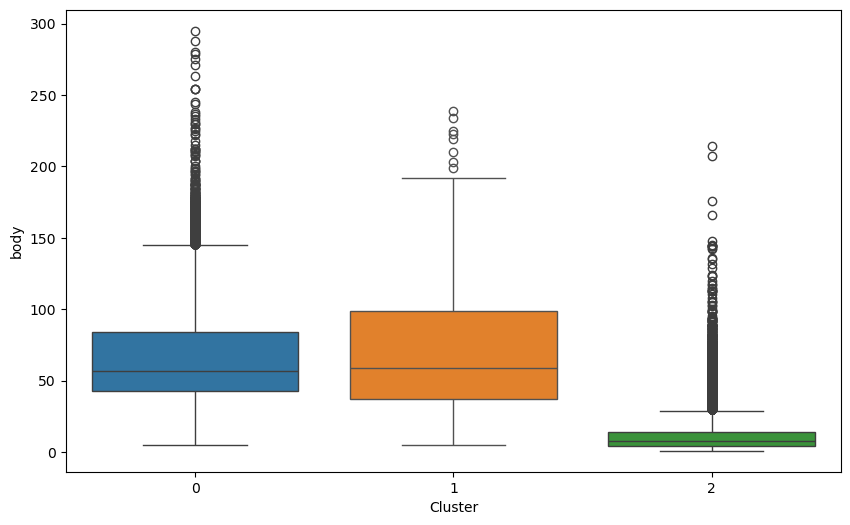

In [16]:
#plot for each cluster the length of comments (boxplot)
plt.figure(figsize=(10, 6))
for i in range(numberOfChoosenClusters):
    cluster_data = data[data['cluster'] == i]
    sns.boxplot(x=cluster_data['cluster'], y=cluster_data['body'].apply(lambda x: len(x.split())))
plt.xlabel('Cluster')

#print for each cluster average length of comments, max, min 25th percentile, 75th percentile
for i in range(numberOfChoosenClusters):
    cluster_data = data[data['cluster'] == i]
    comment_lengths = cluster_data['body'].apply(lambda x: len(x.split()))
    print(f"Cluster {i}:")
    print(f"  Min length: {comment_lengths.min()} words")
    print(f"  25th percentile: {comment_lengths.quantile(0.25)} words")
    print(f"  Average length: {comment_lengths.mean():.2f} words")
    print(f"  75th percentile: {comment_lengths.quantile(0.75)} words")
    print(f"  Max length: {comment_lengths.max()} words")


In [17]:
#store cluster labels in case we want to analyze further later
np.save('kmeans_cluster_labels.npy', data['cluster'].values)